# HOMEWORK 16 - Course Project

Done by: **Bohdan Pinchuk**

Link: https://github.com/BogdanPinchuk/ComputerVision-PBY_HW16_Course_Project

- **Dataset:** BSD432 / CBSD432 (train), BSD68 / CBSD68 (test)
- **Тип задачі:** Тема 2 — Intelligent Denoising based on Autoencoders
- **Вимога курсового проєкту:** обов'язкове порівняння з фільтрацією Гауса
- **Узгодження з лектором (Ján Koloda):** затверджено напрям Denoising; схвалено датасети родини BSD та генерацію шуму «на льоту» як аугментацію
- **Мета:** дослідити та порівняти ефективність класичного бейслайну (фільтр Гауса, медіанний фільтр), згорткового автоенкодера (CNN) та спектрального підходу (Fourier KAN)

---

### Контекст задачі (Motivation)

Потрібно побудувати та дослідити пайплайн для інтелектуального усунення шуму із цифрових зображень (як чорно-білих, так і кольорових).

Відповідно до вимог теми 2 курсового проєкту, ключовими завданнями є:
- порівняння якості денойзингу відносно обов'язкового бейслайну Гауса (*Gaussian filtering*);
- дослідження стійкості алгоритмів до різних типів шуму (гаусівський, періодичний тощо);
- збереження дрібних деталей, контурів та текстур без ефекту «розмиття» (blurring);
- оцінка ефективності, швидкості обробки та сильних/слабких сторін кожного методу.

---
# Поетапний план реалізації проєкту (Roadmap)

## Етап 1 — Data Preparation & Loading (Підготовка та завантаження даних)

Що потрібно зробити:
- підготувати та структурувати каталоги для збереження зображень (`resources/data/`);
- завантажити/зчитати тренувальний набір (BSD432 / CBSD432) та тестовий бенчмарк (BSD68 / CBSD68);
- забезпечити універсальну підтримку як чорно-білих (монохромних), так і кольорових (RGB) зображень.

---

## Етап 2 — EDA & Noise Injection (Аналіз структури та контамінація шумом)

Що потрібно зробити:
- перевірити розмірності, орієнтацію та діапазон значень пікселів у датасеті;
- реалізувати генерацію різних типів шуму «на льоту» як аугментацію (гаусівський шум, періодичні смуги тощо);
- візуалізувати зашумлені зразки та їхній частотний спектр (2D FFT) для аналізу природи шуму.

---

## Етап 3 — Baseline 1: Spatial Filtering (Класична просторова фільтрація)

Що потрібно зробити:
- реалізувати методи просторової фільтрації без навчання:
  - медіанний фільтр для оцінки придушення локальних аномалій;
  - фільтр Гауса (обов'язковий бейслайн за вимогою курсового проєкту);
  - білатеральний фільтр для перевірки збереження меж;
- розрахувати базові метрики відновлення (MSE, MAE, PSNR, SSIM тощо).

---

## Етап 4 — Baseline 2: Convolutional Autoencoder (Базова згорткова нейромережа)

Що потрібно зробити:
- побудувати згортковий автоенкодер (Baseline CNN) із гнучкою функцією активації (SiLU / GELU / LeakyReLU / ELU тощо);
- налаштувати навчальний пайплайн на патчах $64$ x $64$ з оптимізатором;
- проаналізувати криві збіжності функції втрат (Loss) та зафіксувати базову якість.

---

## Етап 5 — Hyperparameter Tuning: Baseline CNN (Підбір гіперпараметрів згорткової мережі)

Що потрібно зробити:
- визначити простір ключових параметрів для оптимізації базової згорткової мережі (активації, швидкість навчання тощо);
- виконати цільовий пошук оптимальної конфігурації через Optuna на підвибірці патчів для досягнення максимальної якості CNN;
- зафіксувати найкращі параметри та зберегти оптимізовану модель бейслайну.

---

## Етап 6 — Novel Model: Fourier KAN (Спектральний автоенкодер)

Що потрібно зробити:
- побудувати архітектуру Fourier KAN із нелінійними вагами на базі гармонійних ядер;
- провести базове навчання моделі за ідентичних умов (той самий датасет і кількість епох для чесного порівняння);
- проаналізувати початкову динаміку навчання та спектральні особливості.

---

## Етап 7 — Hyperparameter Tuning: Fourier KAN (Підбір гіперпараметрів спектральної моделі)

Що потрібно зробити:
- визначити простір ключових параметрів для оптимізації спектральної моделі (гармонійні сітки, параметри оптимізації тощо);
- виконати цільовий пошук оптимальних конфігурацій через Optuna на підвибірці патчів для досягнення максимальної ефективності Fourier KAN;
- зафіксувати найкращі конфігурації та навчити фінальну спектральну модель.

---

## Етап 8 — Benchmarking & Evaluation (Зведена таблиця метрик)

Що потрібно зробити:
- протестувати всі три підходи на контрольному наборі BSD68 / CBSD68;
- розрахувати готові бібліотечні метрики: попіксельні помилки та якість сприйняття (MSE, RMSE, MAE, PSNR, SSIM тощо);
- виміряти швидкість обробки одного кадру (Latency в мс) та кількість параметрів кожної моделі;
- побудувати зведену форматовану таблицю порівняння через `Reporter`.

---

## Етап 9 — Visual & Spectral Analysis (Візуальна та спектральна діагностика)

Що потрібно зробити:
- побудувати радіальний графік спектра енергії (Radial Power Spectrum) для перевірки збереження високих частот і текстур;
- сформувати порівняльну візуальну сітку відновлених зображень;
- побудувати карти залишкових помилок (Residual Error Maps) для наочної демонстрації сильних і слабких сторін кожного підходу.

---

## Етап 10 — Conclusions & Discussion (Висновки та підсумки)

Що потрібно зробити:
- узагальнити отримані результати за основними критеріями оцінювання проєкту;
- сформувати чіткі підсумкові тези (ефективність методів, швидкість роботи, висновки щодо спектрального підходу).

In [1]:
# # Silent installation or update
#
# import sys
# from packaging.requirements import Requirement
# from importlib.metadata import PackageNotFoundError, version
#
# # Clean cache
# !"{sys.executable}" -m pip cache purge -q
#
# # Force updating
# package_update = [
#     "pip",
#     "scikit-learn",
#     "pandas",
# ]
#
# for package_name in package_update:
#     !"{sys.executable}" -m pip install -U "{package_name}" -q
#
# # Install missing packages
# package_array = [
#     "jinja2",
#     "ipywidgets",
#     "nbformat",
#     "numpy",
#     "matplotlib",
#     "opencv-contrib-python",
#     "torch",
#     "torchvision",
#     "scikit-image",
#     "optuna",
#     "seaborn",
# ]
#
#
# def is_package_satisfied(req_str: str) -> bool:
#     try:
#         req = Requirement(req_str)
#         installed_ver = version(req.name)
#         if req.specifier:
#             return installed_ver in req.specifier
#         return True
#     except PackageNotFoundError:
#         return False
#
#
# for package_name in package_array:
#     if not is_package_satisfied(package_name):
#         !"{sys.executable}" -m pip install "{package_name}" -q


In [2]:
# # Synchronization with remote source
#
# import shutil
# from pathlib import Path
#
# # Input data
# hm_version = 16
#
# # Solution
# git_project_url = f"https://github.com/BogdanPinchuk/ComputerVision-PBY_HW{hm_version}_Course_Project.git"
# main_file_name_ua = f"Bohdan_Pinchuk_CV_HW{hm_version}_UA.ipynb"
# main_file_name = f"Bohdan_Pinchuk_CV_HW{hm_version}.ipynb"
#
# # upload all files
# current_path = !pwd
# current_path = current_path[0]
# parent_path = !dirname "$current_path"
# parent_path = parent_path[0]
# temp_path = f"{parent_path}/temp"
#
# # Clone data
# !rm -rf "$temp_path"
# !git clone "$git_project_url" "$temp_path"
#
# source = Path(temp_path)
# destination = Path(current_path)
# exclude = {main_file_name_ua, main_file_name, ".git", ".idea", ".DS_Store"}
#
# for item in source.iterdir():
#     if item.name in exclude:
#         continue
#
#     target = destination / item.name
#     if item.is_dir():
#         shutil.copytree(item, target, dirs_exist_ok=True)
#     else:
#         shutil.copy2(item, target)
#
# # Clean temp folder
# !rm -rf "$temp_path"
#
# # Note. To upload big files to GitHub, execute the next command in the terminal
# # 1. brew install git-lfs
# # 2. git lfs install
# # 3.1. git lfs track "*.safetensors"
# # 3.2. git lfs track "*.bin"

## ✅ Рішення: Етап 1 — Data Preparation & Loading (Підготовка та завантаження даних)

Що потрібно зробити:
- підготувати та структурувати каталоги для збереження зображень (`resources/data/`);
- завантажити/зчитати тренувальний набір (BSD432 / CBSD432) та тестовий бенчмарк (BSD68 / CBSD68);
- забезпечити універсальну підтримку як чорно-білих (монохромних), так і кольорових (RGB) зображень.

In [3]:
# Downloading data

import os
import cv2
import zipfile
import importlib
import numpy as np
from pathlib import Path

from tifffile import imshow

# has to be set before keras is imported
os.environ['KERAS_BACKEND'] = 'torch'
os.environ['KERAS_HOME'] = os.path.abspath('resources/data')
from keras.utils import get_file
from itertools import islice
from PIL import Image
import apps.reporter as rpt

importlib.reload(rpt)

# Input data
n_preview_samples = 4
rng_seed = 42
folder_name = "resources/data"
dataset_zip_url_c = "https://github.com/liutianlin0121/BSD-432-68/archive/refs/heads/master.zip"
archive_name = "cbsd_432_68.zip"
train_c_name = "CBSD432"
test_c_name = "CBSD68"
train_bw_name = "BSD432"
test_bw_name = "BSD68"

# Solution
folder_path = Path(folder_name)
folder_path.mkdir(parents=True, exist_ok=True)

archive_path = folder_path / archive_name
train_c_dir = folder_path / train_c_name
test_c_dir = folder_path / test_c_name
train_bw_dir = folder_path / train_bw_name
test_bw_dir = folder_path / test_bw_name

# download archive
if not archive_path.exists():
    get_file(fname=archive_name,
             origin=dataset_zip_url_c,
             extract=False,
             cache_dir=str(folder_path.parent.resolve()),
             cache_subdir="data")

# check is need to extract
need_extract = not (train_c_dir.exists() and test_c_dir.exists() and
                    len(list(islice(train_c_dir.glob("*.jpg"), 432))) == 432 and
                    len(list(islice(test_c_dir.glob("*.jpg"), 68))) == 68)

# download and extract dataset
if need_extract:
    # check folders
    train_c_dir.mkdir(parents=True, exist_ok=True)
    test_c_dir.mkdir(parents=True, exist_ok=True)
    target_mapping = {
        f"{train_c_name}/": train_c_dir,
        f"{test_c_name}/": test_c_dir,
    }
    # extract
    with zipfile.ZipFile(archive_path, "r") as zf:
        for member in zf.namelist():
            if member.endswith((".jpg", ".png")):
                for prefix, target_dir in target_mapping.items():
                    if prefix in member:
                        filename = os.path.basename(member)
                        if filename:
                            with zf.open(member) as src, open(target_dir / filename, "wb") as dst:
                                dst.write(src.read())
                        break

# check is need to convert
need_convert = not (
        train_bw_dir.exists() and test_bw_dir.exists() and
        len(list(islice(train_bw_dir.glob("*.png"), 432))) == 432 and
        len(list(islice(test_bw_dir.glob("*.png"), 68))) == 68
)

# convert dataset
if need_convert:
    # check folders
    train_bw_dir.mkdir(parents=True, exist_ok=True)
    test_bw_dir.mkdir(parents=True, exist_ok=True)
    pairs = [
        (train_c_dir, train_bw_dir),
        (test_c_dir, test_bw_dir)
    ]
    for src_dir, dst_dir in pairs:
        for img_path in sorted(src_dir.glob("*.jpg")):
            bw_img_path = dst_dir / f"{img_path.stem}.png"
            if not bw_img_path.exists():
                with Image.open(img_path) as img:
                    img.convert("L").save(bw_img_path, format="PNG")

# samples for inspection
train_c_files_all = sorted(list(train_c_dir.glob("*.jpg")))
test_c_files = sorted(list(test_c_dir.glob("*.jpg")))
train_bw_files_all = sorted(list(train_bw_dir.glob("*.png")))
test_bw_files = sorted(list(test_bw_dir.glob("*.png")))

# images
example_img_path = train_c_files_all[0]
example_img_bgr = cv2.imread(str(example_img_path))
if example_img_bgr is None:
    raise FileNotFoundError(f"File read error: {example_img_path}")
sample_c = cv2.cvtColor(example_img_bgr, cv2.COLOR_BGR2RGB)
sample_bw = cv2.imread(str(train_bw_files_all[0]), cv2.IMREAD_GRAYSCALE)

rp = rpt.Reporter()
rp.add_item("Dataset directory", folder_name)
rp.add_item("Saved archive", f"{archive_path.name}")
rp.add_item("Color Train (CBSD432)", f"{len(train_c_files_all)} images")
rp.add_item("Color Test (CBSD68)", f"{len(test_c_files)} images")
rp.add_item("Grayscale Train (BSD432)", f"{len(train_bw_files_all)} images")
rp.add_item("Grayscale Test (BSD68)", f"{len(test_bw_files)} images")
# Print results
rp.print_pd_report("Report of Berkeley Segmentation Dataset (BSD) Inspection")

Attribute,Result
Dataset directory,resources/data
Saved archive,cbsd_432_68.zip
Color Train (CBSD432),432 images
Color Test (CBSD68),68 images
Grayscale Train (BSD432),432 images
Grayscale Test (BSD68),68 images


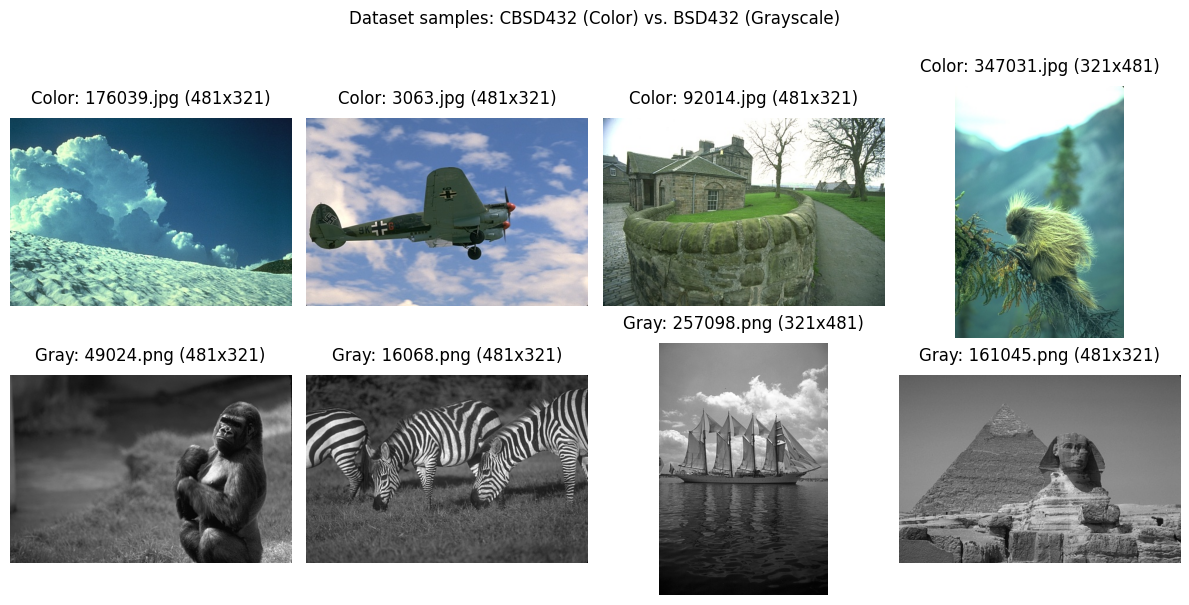

In [4]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = 4

# Solution
preview_samples = []
# get random images: color
random_indices = np.random.choice(len(train_c_files_all), size=n_preview_samples, replace=False)
# add images to list
for idx in random_indices:
    img_path = train_c_files_all[idx]
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise FileNotFoundError(f"File read error: {img_path}")
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    # add images to list
    preview_samples.append((f"Color: {img_path.name} ({img_rgb.shape[1]}x{img_rgb.shape[0]})", img_rgb))

# get random images: grayscale
random_indices = np.random.choice(len(train_bw_files_all), size=n_preview_samples, replace=False)
# add images to list
for idx in random_indices:
    img_path = train_bw_files_all[idx]
    img_gray = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
    if img_gray is None:
        raise FileNotFoundError(f"File read error: {img_path}")
    # add images to list
    preview_samples.append((f"Gray: {img_path.name} ({img_gray.shape[1]}x{img_gray.shape[0]})", img_gray))

images_list = preview_samples
n_img_rows = math.ceil(len(images_list) / n_img_cols)

_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 3 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_list):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_list), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("Dataset samples: CBSD432 (Color) vs. BSD432 (Grayscale)", y=1.0)
plt.tight_layout()
plt.show()


## ✅ Рішення: Етап 2 — EDA & Noise Injection (Аналіз структури та контамінація шумом)

Що потрібно зробити:
- зчитати зображення та проаналізувати орієнтації кадру (Landscape vs Portrait) і розподіл інтенсивностей пікселів;
- розрахувати глобальні характеристики датасету (Mean, Std, Min, Max);
- реалізувати функції генерації шуму «на льоту» (адитивний білий гаусівський шум AWGN із різними $\sigma$ та періодичний смуговий шум);
- дослідити природу шуму в частотній області за допомогою двовимірного перетворення Фур'є (2D FFT).

In [5]:
# Splitting data

import importlib
import apps.main as mn

importlib.reload(mn)

# Input data
val_ratio = len(test_c_files) / len(train_c_files_all)

# Solution
train_c_files, val_c_files = mn.train_test_split_by_order(train_c_files_all, test_size=val_ratio)
train_bw_files, val_bw_files = mn.train_test_split_by_order(train_bw_files_all, test_size=val_ratio)

# Print results


In [6]:
# Form image metadata dataset

import cv2
import numpy as np
import pandas as pd
from IPython.display import display
from IPython.core.display import Markdown

# Input data
n_first_rows = 5
pd.options.display.float_format = '{:g}'.format
datasets_map = {
    (train_c_name, "train"): train_c_files,
    (train_c_name, "validation"): val_c_files,
    (test_c_name, "test"): test_c_files,
    (train_bw_name, "train"): train_bw_files,
    (train_bw_name, "validation"): val_bw_files,
    (test_bw_name, "test"): test_bw_files,
}

# Solution
records = []

# extract necessary data
for (dataset_name, split_type), file_paths in datasets_map.items():
    color_type = "color" if dataset_name in [train_c_name, test_c_name] else "grayscale"

    # analysis image
    for img_path in file_paths:
        # load image
        img = cv2.imread(str(img_path), cv2.IMREAD_UNCHANGED)
        if img is None:
            raise FileNotFoundError(f"Failed to read the file: {img_path}")

        # get channels dimensions
        channels = img.shape[2] if img.ndim == 3 else 1
        height, width = img.shape[:2]
        aspect_ratio = round(width / height, 4)

        # get orientation
        if width > height:
            orientation = "landscape"
        elif height > width:
            orientation = "portrait"
        else:
            orientation = "square"

        # calculate brightness and rms contrast
        min_brightness = int(np.min(img))
        max_brightness = int(np.max(img))
        mean_brightness = float(np.mean(img))
        rms_contrast = float(np.std(img))

        records.append({
            "dataset": dataset_name,
            "split": split_type,
            "color_type": color_type,
            "channels": channels,
            "height": height,
            "width": width,
            "aspect_ratio": aspect_ratio,
            "orientation": orientation,
            "min_brightness": min_brightness,
            "max_brightness": max_brightness,
            "mean_brightness": round(mean_brightness, 2),
            "rms_contrast": round(rms_contrast, 2),
            "file_name": img_path.name,
            "file_path": str(img_path),
        })

# form dataframe
df_images = pd.DataFrame(records)

col_num_type = df_images.select_dtypes(include=np.number)

# Print results
display(Markdown("### Data Analysis: Image Metadata Dataset"))
display(df_images.head(n_first_rows).style.
        set_caption(f"First {n_first_rows} rows of image metadata").
        format("{:g}", subset=col_num_type.columns))

### Data Analysis: Image Metadata Dataset

,dataset,split,color_type,channels,height,width,aspect_ratio,orientation,min_brightness,max_brightness,mean_brightness,rms_contrast,file_name,file_path
0,CBSD432,train,color,3,321,481,1.4984,landscape,16,255,171.82,51.54,100007.jpg,resources/data/CBSD432/100007.jpg
1,CBSD432,train,color,3,321,481,1.4984,landscape,8,255,123.89,54.43,100039.jpg,resources/data/CBSD432/100039.jpg
2,CBSD432,train,color,3,321,481,1.4984,landscape,2,255,91.74,40.02,100075.jpg,resources/data/CBSD432/100075.jpg
3,CBSD432,train,color,3,481,321,0.6674,portrait,17,231,97.11,33.82,100080.jpg,resources/data/CBSD432/100080.jpg
4,CBSD432,train,color,3,321,481,1.4984,landscape,0,255,128.37,80.1,100098.jpg,resources/data/CBSD432/100098.jpg


In [7]:
# Analysis of the datasets

import importlib
import numpy as np
import pandas as pd
from IPython.display import display
from IPython.core.display import Markdown
import apps.reporter as rpt

importlib.reload(rpt)

# Input data
split_col_name = "split"
color_type_col_name = "color_type"
path_col_name = "file_path"
file_name_col_name = "file_name"
mean_brightness_col_name = "mean_brightness"

# Solution
data_set = df_images

n_columns = data_set.columns.size
n_rows = data_set.index.size
num_unique_scenes = df_images[file_name_col_name].nunique()

col_num_type = data_set.select_dtypes(include=np.number)
col_cat_type = data_set.drop([path_col_name, file_name_col_name], axis=1, errors='ignore').select_dtypes(
    exclude=np.number)

for col_name in col_cat_type:
    data_set[col_name] = data_set[col_name].astype('category')

types_df = pd.DataFrame(data_set.dtypes, columns=["Types"])

empty_val_by_col = data_set.isna().sum().to_frame(name='count')
is_empty_val = empty_val_by_col.values.sum() > 0

rp = rpt.Reporter()
rp.add_item("Total images (metadata rows)", str(n_rows))
rp.add_item("Unique image scenes (file names)", str(num_unique_scenes))
rp.add_item("Number of metadata columns", str(n_columns))
rp.add_item("Number of numerical features", str(col_num_type.columns.size))
rp.add_item("Number of categorical features", str(col_cat_type.columns.size))
rp.add_item("Missing values", "None" if not is_empty_val else "Present")

df_split_color_crosstab = pd.crosstab(
    data_set[split_col_name],
    data_set[color_type_col_name],
    margins=True,
    margins_name="Total"
)

# Print results
display(Markdown("### Exploratory Data Analysis: Image Metadata & Distribution"))
rp.print_pd_report("Dataset General Overview")

if is_empty_val:
    display(empty_val_by_col.style.set_caption("Missing Values Count"))
display(types_df.style.set_caption("Feature Data Types"))

display(col_num_type.describe().T.style.
        set_caption("Summary Statistics for Numerical Image Features").format("{:g}"))
display(col_cat_type.describe().T.style.
        set_caption("Summary Statistics for Categorical Image Features"))

for col_name in col_cat_type:
    cat_summary = pd.DataFrame({
        "Count": data_set[col_name].value_counts(),
        "Proportion": data_set[col_name].value_counts(normalize=True)
    })
    display(cat_summary.style.
            set_caption(f"Category Distribution: \"{col_name}\"").
            format({"Count": "{:g}", "Proportion": "{:.2%}"}))

display(df_split_color_crosstab.style.
        set_caption("Cross-Tabulation: Data Split vs Color Representation").
        format("{:g}"))


### Exploratory Data Analysis: Image Metadata & Distribution

Attribute,Result
Total images (metadata rows),1000
Unique image scenes (file names),1000
Number of metadata columns,14
Number of numerical features,8
Number of categorical features,4
Missing values,None


,Types
dataset,category
split,category
color_type,category
channels,int64
height,int64
width,int64
aspect_ratio,float64
orientation,category
min_brightness,int64
max_brightness,int64


,count,mean,std,min,25%,50%,75%,max
channels,1000,2,1.0005,1,1,2,3,3
height,1000,369.64,73.634,321,321,321,481,481
width,1000,432.36,73.634,321,321,481,481,481
aspect_ratio,1000,1.24578,0.382437,0.6674,0.6674,1.4984,1.4984,1.4984
min_brightness,1000,7.17,10.7253,0,0,1,12.25,55
max_brightness,1000,251.75,9.76867,166,253,255,255,255
mean_brightness,1000,106.984,27.4116,31.36,88.475,107.73,125.11,212.08
rms_contrast,1000,52.756,14.3446,12.15,42.4825,52.38,63,114.07


,count,unique,top,freq
dataset,1000,4,CBSD432,432
split,1000,3,train,728
color_type,1000,2,color,500
orientation,1000,2,landscape,696


,Count,Proportion
dataset,,
BSD432,432,43.20%
CBSD432,432,43.20%
BSD68,68,6.80%
CBSD68,68,6.80%


,Count,Proportion
split,,
train,728,72.80%
test,136,13.60%
validation,136,13.60%


,Count,Proportion
color_type,,
color,500,50.00%
grayscale,500,50.00%


,Count,Proportion
orientation,,
landscape,696,69.60%
portrait,304,30.40%


color_type,color,grayscale,Total
split,,,
test,68,68,136
train,364,364,728
validation,68,68,136
Total,500,500,1000


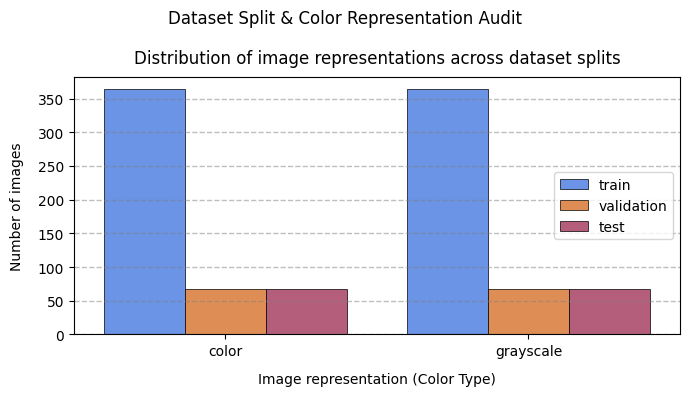

In [8]:
# Graphic results

import seaborn as sns
import matplotlib.pyplot as plt

# Input data
data_set = df_images[[split_col_name, color_type_col_name]]
split_order = data_set[split_col_name].unique().tolist()
x_indices = data_set[color_type_col_name].unique().tolist()

# Solution
_, ax = plt.subplots(figsize=(7, 4))

sns.countplot(data=data_set, ax=ax, x=color_type_col_name, hue=split_col_name, hue_order=split_order,
              edgecolor='black', linewidth=0.5)

ax.set_xticks(x_indices)
ax.tick_params(axis='x', which='minor', bottom=False, top=False)

ax.grid(axis='y', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='y', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Distribution of image representations across dataset splits", pad=10, loc='center', color='black')
ax.set_xlabel("Image representation (Color Type)", labelpad=10, loc='center', color='black')
ax.set_ylabel("Number of images", labelpad=10, loc='center', color='black')

ax.legend(frameon=True, loc='center right')
plt.suptitle("Dataset Split & Color Representation Audit")

plt.tight_layout()
plt.show()


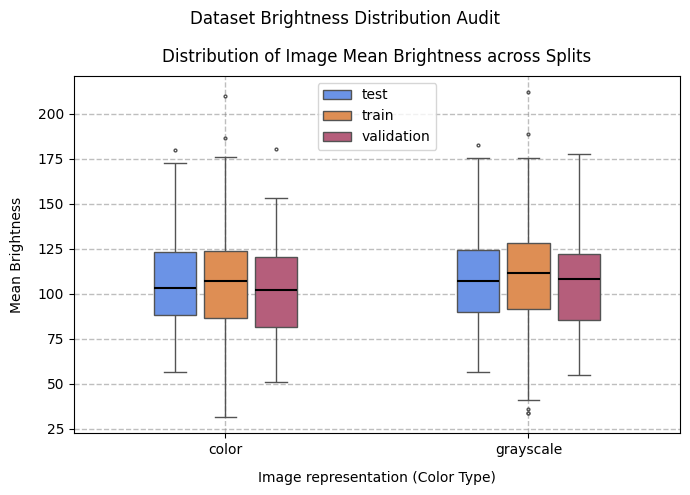

In [9]:
# Graphic results

import matplotlib.pyplot as plt
import seaborn as sns

# Input data
data_set = df_images[[split_col_name, color_type_col_name, mean_brightness_col_name]]
split_order = data_set[split_col_name].unique().tolist()
x_indices = data_set[color_type_col_name].unique().tolist()

# Solution
_, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(data=data_set, ax=ax, x=color_type_col_name, y=mean_brightness_col_name, hue=split_col_name,
            width=0.5, gap=0.15, medianprops={"linewidth": 1.5, "color": "black"}, fliersize=2)

ax.set_xticks(x_indices)
ax.tick_params(axis='x', which='minor', bottom=False, top=False)

ax.grid(axis="both", visible=True, which="major", ls="--", linewidth=1.0, color="tab:gray")
# ax.minorticks_on()
# ax.grid(axis='y', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Distribution of Image Mean Brightness across Splits", pad=10, loc="center", color="black")
ax.set_xlabel("Image representation (Color Type)", labelpad=10, loc="center", color="black")
ax.set_ylabel("Mean Brightness", labelpad=10, loc="center", color="black")

ax.legend(frameon=True, loc="upper center")
plt.suptitle("Dataset Brightness Distribution Audit")

plt.tight_layout()
plt.show()


In [10]:
# Example of the slicing

import cv2
import importlib
import numpy as np
import apps.main as mn

importlib.reload(mn)

# Input data
patch_size = (64, 64)

# Solution
is_color = bool(np.random.choice([True, False]))
train_files = train_c_files if is_color else train_bw_files

random_img_idx = np.random.choice(len(train_files))
example_img_path = train_files[random_img_idx]
example_img = cv2.imread(str(example_img_path), cv2.IMREAD_UNCHANGED)
if example_img is None:
    raise FileNotFoundError(f"File read error: {example_img_path}")

# processing color image
if example_img.ndim == 3:
    example_img = cv2.cvtColor(example_img, cv2.COLOR_BGR2RGB)

example_patches = mn.image_slicer(example_img, patch_size, is_flat=False)

# Print results
display(Markdown("### Image Tiling & Patch Extraction"))


### Image Tiling & Patch Extraction

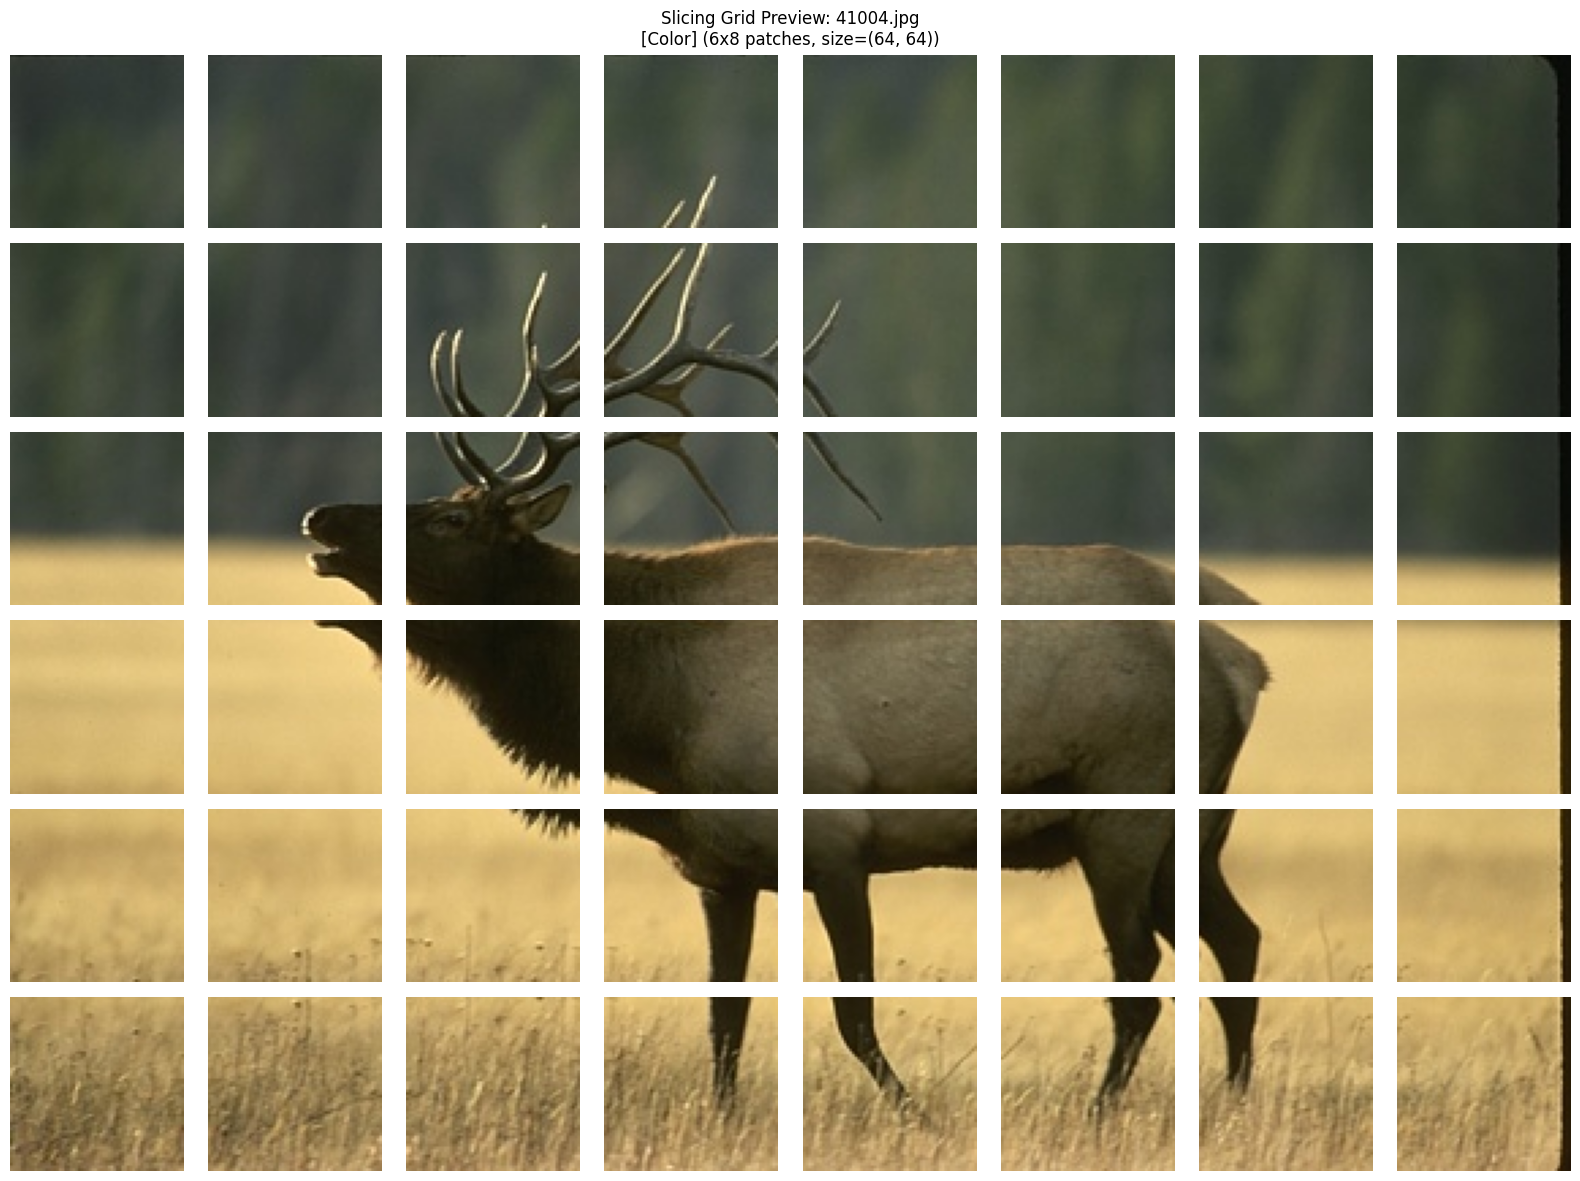

In [11]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = len(example_patches[0])
images_list = [patch for row in example_patches for patch in row]

# Solution
img_type_label = "Color" if example_img.ndim == 3 else "Grayscale"
n_img_rows = math.ceil(len(images_list) / n_img_cols)

_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(2 * n_img_cols, 2 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, img_data in enumerate(images_list):
    ax = axes_list[idx]
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray', vmin=0, vmax=255)
    ax.axis(False)

# remove empty charts
for idx in range(len(images_list), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle(
    f"Slicing Grid Preview: {example_img_path.name}\n[{img_type_label}] ({n_img_rows}x{n_img_cols} patches, size={patch_size})")
plt.tight_layout()
plt.show()


In [12]:
# Example of noise

# Input data

# Solution

# Print results



In [13]:
# template

# Input data

# Solution

# Print results
